# GLM Encoding Model Fitting

This notebook fits a Generalized Linear Model (GLM) to predict neural activity from task predictors.

**Training Strategy:**
- **One single model** trained on balanced data combined from all 3 contexts (CG=0, visual=1, audio=2)
- Each context contributes 70% of its balanced L/R trials to training; 30% to test
- Model is tested on: (a) combined held-out data from all contexts; (b) held-out data per context individually

**Predictor groups (9 total after reparameterization):**
- `position_only` (10), `audio_context` (10), `audio_stim` (10), `visual_context` (10), `visual_stim` (10)
- `velocity` (20), `choice_spatial` (60), `turn_onset` (8), `outcome` (12: 6 correct + 6 error)

**Model:**
- Poisson GLM with exponential activation
- Group Lasso regularization (groups can be fully zeroed out)
- 4-fold cross-validation across 5 lambda values (1e-3 to 1e-6)
- Neuron categorization uses **RMS-normalized** group L2 norms (L2 / sqrt(group_size)) for fair comparison

## 1. Imports and Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
import scipy.stats
import os
from matplotlib import rcParams
import sys
import tensorflow as tf
import multiprocessing

# Import GLM classes
sys.path.insert(0, '/Users/akhilbandi/Documents/Portfolio/code_projects/Context Paper Code/GLM_encoding_model')
import glm_class
from glm_class import make_prediction, deviance

# Set plotting style
rcParams['font.family'] = 'Arial'
rcParams['axes.spines.right'] = False
rcParams['axes.spines.top'] = False

print("✓ Imports complete")

✓ Imports complete


## 2. Load and Clean Data

In [2]:
# Define dataset
mouse_ID = 'KO-5-1L' 
date = '2026-03-05'

In [3]:
import gzip
import pickle

save_path = f'/Volumes/Akhil Data/Akhil/ProcessedData/{mouse_ID}/{date}/glm_data_dict.pkl.gz'
with gzip.open(save_path, 'rb') as f:
    glm_data_dict = pickle.load(f)

In [4]:
load_path = f'/Volumes/Akhil Data/Akhil/ProcessedData/{mouse_ID}/{date}/glm_data_stacked.pkl'
print(f"Loading data from: {load_path}")

with open(load_path, 'rb') as f:
    glm_data = pickle.load(f)

# Extract components
X = glm_data['X']  # Already z-scored
Y = glm_data['Y'] * 10  # Scaled by 10 for deconv
metadata = glm_data['metadata']
predictor_names = glm_data['predictor_names']
predictor_info = glm_data['predictor_info'].copy()  # Make a copy to modify
group_indices = glm_data['group_indices']

print(f"\n✓ Data loaded successfully!")
print(f"  X shape: {X.shape} (frames × predictors)")
print(f"  Y shape: {Y.shape} (frames × neurons)")

print(f"\nFinal data shapes:")
print(f"  X: {X.shape}")
print(f"  Y: {Y.shape}")
print(f"  Predictor groups: {list(predictor_info.keys())}")

Loading data from: /Volumes/Akhil Data/Akhil/ProcessedData/KO-5-1L/2026-03-05/glm_data_stacked.pkl

✓ Data loaded successfully!
  X shape: (88045, 150) (frames × predictors)
  Y shape: (88045, 883) (frames × neurons)

Final data shapes:
  X: (88045, 150)
  Y: (88045, 883)
  Predictor groups: ['position_only', 'sound', 'visual', 'velocity', 'choice_spatial', 'turn_onset', 'outcome']


### Verify Data Preprocessing

Check that X and Y are properly formatted per Harvey Lab tutorial

In [5]:
print("Data Verification")
print("="*60)

# Check X (design matrix)
print("\nX (Design Matrix):")
print(f"  Mean: {np.mean(X):.6f} (should be ≈0)")
print(f"  Std:  {np.std(X):.3f} (should be ≈1)")
print(f"  Range: [{np.min(X):.2f}, {np.max(X):.2f}]")
print(f"  NaN count: {np.sum(np.isnan(X))}")
print(f"  Inf count: {np.sum(np.isinf(X))}")

# Check Y (neural data)
print("\nY (Neural Data):")
print(f"  Mean: {np.mean(Y):.3f}")
print(f"  Std:  {np.std(Y):.3f}")
print(f"  Range: [{np.min(Y):.2f}, {np.max(Y):.2f}]")
print(f"  NaN count: {np.sum(np.isnan(Y))}")
print(f"  Inf count: {np.sum(np.isinf(Y))}")

# Check metadata
print("\nMetadata (Context distribution):")
for ctx in [0, 1, 2]:
    n_frames = np.sum(metadata['context'] == ctx)
    pct = n_frames / len(metadata['context']) * 100
    print(f"  Context {ctx}: {n_frames:,} frames ({pct:.1f}%)")

print("\n✓ Data verification complete")

Data Verification

X (Design Matrix):
  Mean: 0.000000 (should be ≈0)
  Std:  0.998 (should be ≈1)
  Range: [-12.26, 52.22]
  NaN count: 0
  Inf count: 0

Y (Neural Data):
  Mean: 0.015
  Std:  0.182
  Range: [0.00, 17.44]
  NaN count: 0
  Inf count: 0

Metadata (Context distribution):
  Context 0: 17,406 frames (19.8%)
  Context 1: 32,009 frames (36.4%)
  Context 2: 38,630 frames (43.9%)

✓ Data verification complete


## 3. Train/Test Split

Balance L/R choices within each context, then do 70/30 trial-level split.
Training data = 70% of each context combined.
Test data = 30% of each context (used combined and per-context).

In [6]:
# Train/test splitting is done inside the combined fitting cell below.
# Balanced L/R trials per context, 70/30 split, combined across contexts.
pass

In [7]:
import pandas as pd
from sklearn.model_selection import train_test_split

# Context-specific balancing and 70/30 splitting are handled inside
# the 3-context fitting loop in Section 4.

print("✓ Imports ready (pd, train_test_split)")

✓ Imports ready (pd, train_test_split)


### Prepare Feature Groups for Group Lasso

Split `sound` into `audio_context` + `audio_stim` and `visual` into `visual_context` + `visual_stim`.
All 9 groups are used in the single combined model (no per-context active-group subsetting).

In [8]:
# Split 'sound' and 'visual' groups into 4 interpretable sub-groups
new_predictor_info = {}
for group_name, info in predictor_info.items():
    if group_name == 'sound':
        n_half = (info['end'] - info['start']) // 2
        new_predictor_info['audio_context'] = {
            'start': info['start'],
            'end':   info['start'] + n_half,
            'names': info.get('names', [])[:n_half],
        }
        new_predictor_info['audio_stim'] = {
            'start': info['start'] + n_half,
            'end':   info['end'],
            'names': info.get('names', [])[n_half:],
        }
    elif group_name == 'visual':
        n_half = (info['end'] - info['start']) // 2
        new_predictor_info['visual_context'] = {
            'start': info['start'],
            'end':   info['start'] + n_half,
            'names': info.get('names', [])[:n_half],
        }
        new_predictor_info['visual_stim'] = {
            'start': info['start'] + n_half,
            'end':   info['end'],
            'names': info.get('names', [])[n_half:],
        }
    else:
        new_predictor_info[group_name] = info

predictor_info = new_predictor_info

def get_feature_group_size(pi):
    return np.array([info['end'] - info['start'] for info in pi.values()])

feature_group_size = get_feature_group_size(predictor_info)

print('Predictor groups (all 9 used in combined model):')
print('='*60)
for group_name, info in predictor_info.items():
    n = info['end'] - info['start']
    print(f'  {group_name:20s}: {n:2d} features (cols {info["start"]}-{info["end"]-1})')
print(f'\nTotal: {np.sum(feature_group_size)} features')
print('\n  Single model uses all columns — no per-context subsetting')

Predictor groups (all 9 used in combined model):
  position_only       : 10 features (cols 0-9)
  audio_context       : 10 features (cols 10-19)
  audio_stim          : 10 features (cols 20-29)
  visual_context      : 10 features (cols 30-39)
  visual_stim         : 10 features (cols 40-49)
  velocity            : 20 features (cols 50-69)
  choice_spatial      : 60 features (cols 70-129)
  turn_onset          :  8 features (cols 130-137)
  outcome             : 12 features (cols 138-149)

Total: 150 features

  Single model uses all columns — no per-context subsetting


### Check GPU Availability

In [9]:
print("System Resources:")
print("="*60)
print(f"TensorFlow version: {tf.__version__}")

# Check for Metal GPU on Mac
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f"\n✓ GPU Available: {len(gpus)} device(s)")
    for gpu in gpus:
        print(f"  - {gpu}")
    
    # Enable memory growth
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print("  ✓ Memory growth enabled")
    except:
        pass
else:
    print("\n⚠️  No GPU detected")

# CPU info
n_cores = multiprocessing.cpu_count()
print(f"\nCPU cores: {n_cores}")
print("="*60)

System Resources:
TensorFlow version: 2.16.2

✓ GPU Available: 1 device(s)
  - PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')
  ✓ Memory growth enabled

CPU cores: 24


## 4. Fit Single Combined GLM

Train one GLM on balanced data from all 3 contexts.
Evaluate on combined held-out test set and per-context held-out sets.

In [ ]:
# Single Combined GLM Fitting
# Trains ONE model on balanced data from all 3 contexts combined.

context_names = {0: 'CG', 1: 'visual', 2: 'audio'}
rng = np.random.default_rng(seed=42)

# 1. Per-context balanced 70/30 splits
print('Per-context balanced splits:')
train_masks = {}
test_masks  = {}

for ctx in [0, 1, 2]:
    ctx_frame_mask = metadata['context'] == ctx
    meta_ctx = {k: v[ctx_frame_mask] for k, v in metadata.items()}

    trial_df = (
        pd.DataFrame({'trial_id': meta_ctx['trial_id'],
                      'choice':   meta_ctx['choice']})
        .drop_duplicates(subset='trial_id')
    )

    left_trials  = trial_df[trial_df['choice'] == 0]['trial_id'].to_numpy()
    right_trials = trial_df[trial_df['choice'] == 1]['trial_id'].to_numpy()
    n_bal = min(len(left_trials), len(right_trials))

    if n_bal == 0:
        print(f'  Skipping context {ctx}: insufficient trials.')
        continue

    left_sel  = rng.choice(left_trials,  size=n_bal, replace=False)
    right_sel = rng.choice(right_trials, size=n_bal, replace=False)
    balanced_ids = np.concatenate([left_sel, right_sel])

    bal_df = trial_df[trial_df['trial_id'].isin(balanced_ids)].copy()
    train_trials, test_trials = train_test_split(
        bal_df['trial_id'].to_numpy(),
        test_size=0.3,
        random_state=0,
        stratify=bal_df['choice'],
    )

    ctx_global_idx = np.where(ctx_frame_mask)[0]
    tr_local = np.isin(meta_ctx['trial_id'], train_trials)
    te_local = np.isin(meta_ctx['trial_id'], test_trials)

    train_global = np.zeros(len(metadata['context']), dtype=bool)
    test_global  = np.zeros(len(metadata['context']), dtype=bool)
    train_global[ctx_global_idx[tr_local]] = True
    test_global[ctx_global_idx[te_local]]  = True

    train_masks[ctx] = train_global
    test_masks[ctx]  = test_global

    print(f'  ctx {ctx} ({context_names[ctx]:6s}): {len(balanced_ids)} balanced trials | '
          f'train {train_global.sum():,} frames | test {test_global.sum():,} frames')

# 2. Build combined train / test sets
combined_train_mask = train_masks[0] | train_masks[1] | train_masks[2]
combined_test_mask  = test_masks[0]  | test_masks[1]  | test_masks[2]

X_train = X[combined_train_mask]
Y_train = Y[combined_train_mask]
X_test  = X[combined_test_mask]
Y_test  = Y[combined_test_mask]

print(f'\nCombined train: {X_train.shape[0]:,} frames | test: {X_test.shape[0]:,} frames')
print(f'X_train: {X_train.shape}  |  X_test: {X_test.shape}')

# 3. Instantiate and fit ONE GLM on combined training data
#    NOTE: feature_group_size is passed to .fit(), not __init__
lambda_series = np.logspace(-3, -6, 5)

# Initialize GLM_CV (following Harvey Lab tutorial)
model_cv = glm_class.GLM_CV(
    n_folds=3,
    auto_split=True,
    split_by_group=True,
    activation='exp', #'exp', 'softplus'
    loss_type='poisson', #'poisson', 'gaussian'
    regularization='group_lasso',
    lambda_series=10.0 ** np.linspace(-3, -6, 5),
    l1_ratio=0.95,
    smooth_strength=0.1,
    optimizer='adam',
    learning_rate=1e-2,
    convergence_tol=1e-6
)

print(f'\nFitting single combined GLM ({Y.shape[1]} neurons, '
      f'{X_train.shape[0]:,} frames, {len(feature_group_size)} groups, '
      f'{len(lambda_series)} lambdas)...')
# group_idx ensures CV splits at trial level (no frame-leakage across folds)
group_idx_train = metadata['trial_id'][combined_train_mask]
model_cv.fit(X_train, Y_train,
             feature_group_size=feature_group_size,
             group_idx=group_idx_train)



Per-context balanced splits:
  ctx 0 (CG    ): 72 balanced trials | train 11,201 frames | test 5,247 frames
  ctx 1 (visual): 70 balanced trials | train 11,317 frames | test 4,547 frames
  ctx 2 (audio ): 154 balanced trials | train 24,164 frames | test 10,768 frames

Combined train: 46,682 frames | test: 20,562 frames
X_train: (46682, 150)  |  X_test: (20562, 150)

Fitting single combined GLM (883 neurons, 46,682 frames, 9 groups, 5 lambdas)...


2026-03-09 15:55:52.155110: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M2 Ultra
2026-03-09 15:55:52.155168: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 128.00 GB
2026-03-09 15:55:52.155179: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 53.76 GB
2026-03-09 15:55:52.155198: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-03-09 15:55:52.155208: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


n_fold = 0
Lambda 0 iter 100 loss: 0.42058739 diff: 0.00585278
Lambda 0 iter 200 loss: 0.25431073 diff: 0.00165319
Lambda 0 iter 300 loss: 0.18154813 diff: 0.00072462
Lambda 0 iter 400 loss: 0.14325857 diff: 0.00038165
Lambda 0 iter 500 loss: 0.12069963 diff: 0.00022498
Lambda 0 iter 600 loss: 0.10636783 diff: 0.00014299
Lambda 0 iter 700 loss: 0.09676786 diff: 0.00009580
Lambda 0 iter 800 loss: 0.09008888 diff: 0.00006667
Lambda 0 iter 900 loss: 0.08531434 diff: 0.00004766
Lambda 0 iter 1000 loss: 0.08183005 diff: 0.00003479
Lambda 0 iter 1100 loss: 0.07924344 diff: 0.00002583
Lambda 0 iter 1200 loss: 0.07729642 diff: 0.00001944
Lambda 0 iter 1300 loss: 0.07581397 diff: 0.00001480
Lambda 0 iter 1400 loss: 0.07467450 diff: 0.00001138
Lambda 0 iter 1500 loss: 0.07379163 diff: 0.00000882
Lambda 0 iter 1600 loss: 0.07310352 diff: 0.00000687
Lambda 0 iter 1700 loss: 0.07256386 diff: 0.00000539
Lambda 0 iter 1800 loss: 0.07213888 diff: 0.00000425
Lambda 0 iter 1900 loss: 0.07180294 diff: 0.

ValueError: too many values to unpack (expected 2)

In [ ]:
# 4. Select optimal lambda per neuron
#    se_fraction=0 -> pick lambda with highest deviance explained per neuron
model_cv.select_model(se_fraction=0., make_fig=False)
cv_frac_dev = np.maximum(model_cv.selected_frac_dev_expl_cv, 0.0)
print(f'\nCV frac_dev: median={np.median(cv_frac_dev):.3f} | '
      f'neurons >0.05: {np.sum(cv_frac_dev > 0.05)}/{len(cv_frac_dev)}')

# 5. Evaluate on combined test set
Y_pred_test = make_prediction(
    X_test, model_cv.selected_w, model_cv.selected_w0.flatten(), activation='exp'
)
fd_all, _, _ = deviance(Y_pred_test, Y_test)
test_frac_dev = np.maximum(fd_all, 0.0)
print(f'Test frac_dev (combined): median={np.median(test_frac_dev):.3f} | '
      f'>0.05: {np.sum(test_frac_dev > 0.05)}/{len(test_frac_dev)}')

# 6. Evaluate per-context held-out sets
test_frac_dev_per_ctx = {}
for ctx in [0, 1, 2]:
    X_te_ctx = X[test_masks[ctx]]
    Y_te_ctx = Y[test_masks[ctx]]
    Y_pr_ctx = make_prediction(
        X_te_ctx, model_cv.selected_w, model_cv.selected_w0.flatten(), activation='exp'
    )
    fd_ctx, _, _ = deviance(Y_pr_ctx, Y_te_ctx)
    test_frac_dev_per_ctx[ctx] = np.maximum(fd_ctx, 0.0)
    print(f'  ctx {ctx} ({context_names[ctx]:6s}): median={np.median(test_frac_dev_per_ctx[ctx]):.3f} | '
          f'>0.05: {np.sum(test_frac_dev_per_ctx[ctx] > 0.05)}/{len(test_frac_dev_per_ctx[ctx])}')

# 7. Assemble result dict
all_results = {
    'weights':               model_cv.selected_w,
    'w0':                    model_cv.selected_w0,
    'cv_frac_dev':           cv_frac_dev,
    'test_frac_dev':         test_frac_dev,
    'test_frac_dev_per_ctx': test_frac_dev_per_ctx,
    'predictor_info':        predictor_info,
    'train_masks':           train_masks,
    'test_masks':            test_masks,
    'combined_train_mask':   combined_train_mask,
    'combined_test_mask':    combined_test_mask,
    'feature_group_size':    feature_group_size,
    'context_names':         context_names,
    'mouse_ID':              mouse_ID,
    'date':                  date,
}

# 8. Save
save_dir = f'/Volumes/Akhil Data/Akhil/ProcessedData/{mouse_ID}/{date}/'
os.makedirs(save_dir, exist_ok=True)
save_path = os.path.join(save_dir, 'glm_results_combined.pkl')
with open(save_path, 'wb') as f:
    pickle.dump(all_results, f)

mb = os.path.getsize(save_path) / 1e6
print(f'\n  Saved to {save_path}  ({mb:.2f} MB)')


CV frac_dev: median=0.062 | neurons >0.05: 515/883
Test frac_dev (combined): median=0.064 | >0.05: 525/883
  ctx 0 (CG    ): median=0.051 | >0.05: 448/883
  ctx 1 (visual): median=0.050 | >0.05: 443/883
  ctx 2 (audio ): median=0.054 | >0.05: 464/883

  Saved to /Volumes/Akhil Data/Akhil/ProcessedData/KO-5-1L/2026-03-05/glm_results_combined.pkl  (1.28 MB)


## 5. CV & Test Performance Summary

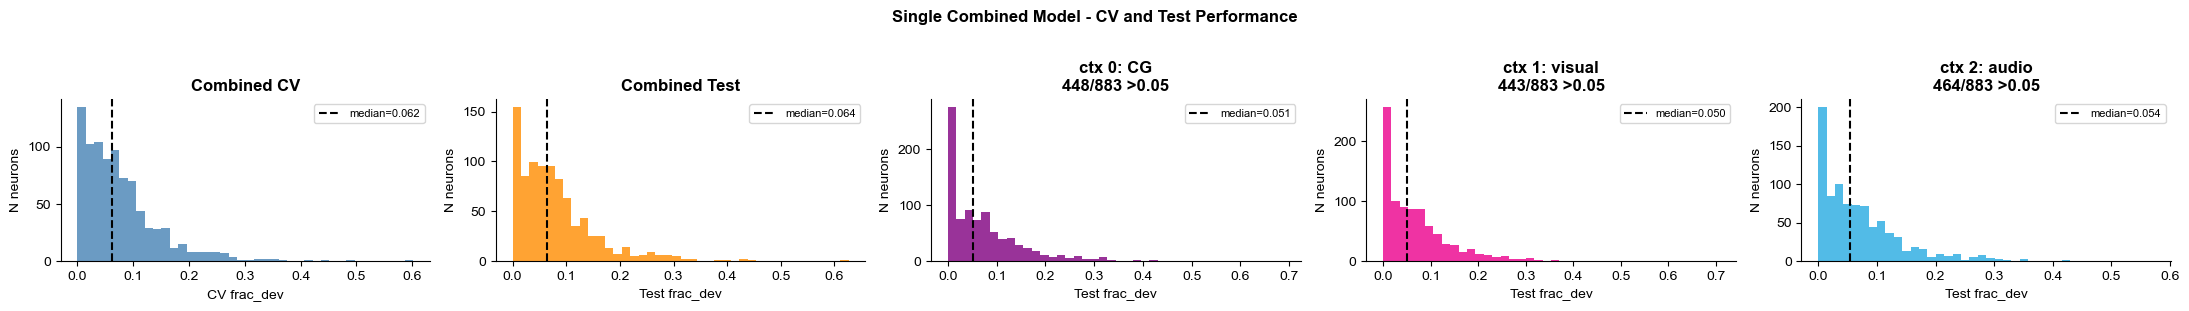

Set                    Median     Mean    >0.05
------------------------------------------------
  Combined CV         0.062    0.077   515/883
  Combined test       0.064    0.079   525/883
  ctx 0 CG      test    0.051    0.074   448/883
  ctx 1 visual  test    0.050    0.070   443/883
  ctx 2 audio   test    0.054    0.073   464/883


In [15]:
context_names = {0: 'CG', 1: 'visual', 2: 'audio'}
colors = {0: 'purple', 1: '#EC008C', 2: '#27AAE1'}

fig, axes = plt.subplots(1, 5, figsize=(22, 3))

# Panel 1: combined CV
ax = axes[0]
ax.hist(all_results['cv_frac_dev'], bins=40, color='steelblue', alpha=0.8, edgecolor='none')
med = np.median(all_results['cv_frac_dev'])
ax.axvline(med, color='k', linestyle='--', linewidth=1.5, label=f'median={med:.3f}')
ax.set_title('Combined CV', fontweight='bold')
ax.set_xlabel('CV frac_dev')
ax.set_ylabel('N neurons')
ax.legend(fontsize=8)

# Panel 2: combined test
ax = axes[1]
ax.hist(all_results['test_frac_dev'], bins=40, color='darkorange', alpha=0.8, edgecolor='none')
med = np.median(all_results['test_frac_dev'])
ax.axvline(med, color='k', linestyle='--', linewidth=1.5, label=f'median={med:.3f}')
ax.set_title('Combined Test', fontweight='bold')
ax.set_xlabel('Test frac_dev')
ax.set_ylabel('N neurons')
ax.legend(fontsize=8)

# Panels 3-5: per-context test
for ax, (ctx, name) in zip(axes[2:], context_names.items()):
    td = all_results['test_frac_dev_per_ctx'][ctx]
    ax.hist(td, bins=40, color=colors[ctx], alpha=0.8, edgecolor='none')
    med = np.median(td)
    ax.axvline(med, color='k', linestyle='--', linewidth=1.5, label=f'median={med:.3f}')
    good = np.sum(td > 0.05)
    n = len(td)
    ax.set_title(f'ctx {ctx}: {name}\n{good}/{n} >0.05', fontweight='bold')
    ax.set_xlabel('Test frac_dev')
    ax.set_ylabel('N neurons')
    ax.legend(fontsize=8)

plt.suptitle('Single Combined Model - CV and Test Performance', fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print(f'{"Set":<20} {"Median":>8} {"Mean":>8} {">0.05":>8}')
print('-' * 48)
n_tot = len(all_results['cv_frac_dev'])
print(f'  Combined CV      {np.median(all_results["cv_frac_dev"]):>8.3f} {np.mean(all_results["cv_frac_dev"]):>8.3f} {np.sum(all_results["cv_frac_dev"] > 0.05):>5}/{n_tot}')
print(f'  Combined test    {np.median(all_results["test_frac_dev"]):>8.3f} {np.mean(all_results["test_frac_dev"]):>8.3f} {np.sum(all_results["test_frac_dev"] > 0.05):>5}/{n_tot}')
for ctx, name in context_names.items():
    td = all_results['test_frac_dev_per_ctx'][ctx]
    print(f'  ctx {ctx} {name:7s} test {np.median(td):>8.3f} {np.mean(td):>8.3f} {np.sum(td > 0.05):>5}/{len(td)}')

## 6. Per-Context Test Performance Comparison

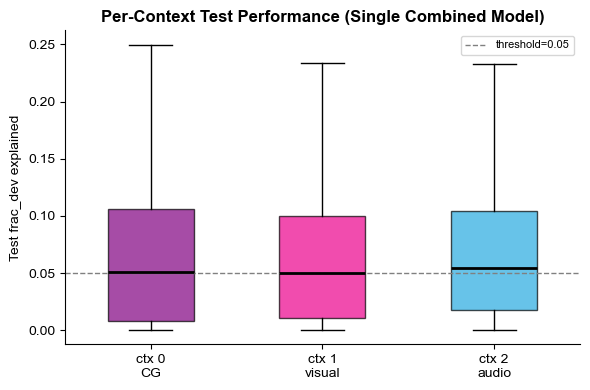

In [16]:
context_names = {0: 'CG', 1: 'visual', 2: 'audio'}
colors = {0: 'purple', 1: '#EC008C', 2: '#27AAE1'}

fig, ax = plt.subplots(figsize=(6, 4))

data_to_plot = [all_results['test_frac_dev_per_ctx'][ctx] for ctx in [0, 1, 2]]
positions = [1, 2, 3]
bp = ax.boxplot(data_to_plot, positions=positions, widths=0.5, patch_artist=True,
                showfliers=False, medianprops=dict(color='k', linewidth=2))

for patch, ctx in zip(bp['boxes'], [0, 1, 2]):
    patch.set_facecolor(colors[ctx])
    patch.set_alpha(0.7)

ax.axhline(0.05, color='gray', linestyle='--', linewidth=1, label='threshold=0.05')
ax.set_xticks(positions)
ax.set_xticklabels([f'ctx {c}\n{context_names[c]}' for c in [0, 1, 2]])
ax.set_ylabel('Test frac_dev explained')
ax.set_title('Per-Context Test Performance (Single Combined Model)', fontweight='bold')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 8. Save / Load Results

In [17]:
# Results are saved inside the fitting cell above.
# To reload without re-fitting:

save_dir = f'/Volumes/Akhil Data/Akhil/ProcessedData/{mouse_ID}/{date}/'
save_path = os.path.join(save_dir, 'glm_results_combined.pkl')

if os.path.exists(save_path):
    mb = os.path.getsize(save_path) / 1e6
    print(f'  Combined model results: {save_path}  ({mb:.2f} MB)')
    # Uncomment to reload:
    # with open(save_path, 'rb') as f:
    #     all_results = pickle.load(f)
    # predictor_info = all_results['predictor_info']
    # feature_group_size = all_results['feature_group_size']
    # context_names = all_results['context_names']
else:
    print(f'  Not found: {save_path}  (run fitting cell first)')

  Combined model results: /Volumes/Akhil Data/Akhil/ProcessedData/KO-5-1L/2026-03-05/glm_results_combined.pkl  (1.28 MB)


## Analyze Beta weights

In [18]:
# Analysis of single combined model weights
context_names = {0: 'CG', 1: 'visual', 2: 'audio'}

threshold = 0.05

good_neurons_mask   = all_results['cv_frac_dev'] > threshold
good_neuron_indices = np.where(good_neurons_mask)[0]
weights_good        = all_results['weights'][:, good_neurons_mask]

print(f'Single combined model: '
      f'{np.sum(good_neurons_mask)} / {len(good_neurons_mask)} neurons '
      f'above {threshold} CV frac_dev threshold')

Single combined model: 515 / 883 neurons above 0.05 CV frac_dev threshold


In [19]:
# All 9 predictor groups are present in the single combined model.
groups_of_interest = list(predictor_info.keys())  # all 9 groups
print(f'Groups of interest ({len(groups_of_interest)}): {groups_of_interest}')

Groups of interest (9): ['position_only', 'audio_context', 'audio_stim', 'visual_context', 'visual_stim', 'velocity', 'choice_spatial', 'turn_onset', 'outcome']


In [20]:
def categorize_neurons_by_modulation(weights, predictor_info, good_neurons_mask,
                                     groups_of_interest=None):
    """
    Categorize each neuron by which predictor group has the strongest modulation.

    Uses RMS-normalized L2 norm (L2 / sqrt(group_size)) so that larger groups
    are not automatically dominant over smaller ones.

    Returns
    -------
    neuron_categories    : dict  group_name -> list of global neuron indices
    modulation_strengths : (n_groups, n_good_neurons) RMS-normalized norms
    """
    if groups_of_interest is None:
        groups_of_interest = list(predictor_info.keys())

    n_good_neurons = np.sum(good_neurons_mask)
    good_idx = np.where(good_neurons_mask)[0]

    modulation_strengths = np.zeros((len(groups_of_interest), n_good_neurons))

    for i, group_name in enumerate(groups_of_interest):
        if group_name not in predictor_info:
            continue
        start = predictor_info[group_name]['start']
        end   = predictor_info[group_name]['end']
        n_features = end - start
        group_weights = weights[start:end, good_neurons_mask]
        # RMS norm: divide by sqrt(group_size) for fair cross-group comparison
        modulation_strengths[i, :] = (
            np.linalg.norm(group_weights, axis=0) / np.sqrt(n_features)
        )

    dominant_group_idx = np.argmax(modulation_strengths, axis=0)

    neuron_categories = {group: [] for group in groups_of_interest}
    neuron_categories['mixed'] = []

    for neuron_idx in range(n_good_neurons):
        max_str    = modulation_strengths[dominant_group_idx[neuron_idx], neuron_idx]
        second_max = (np.partition(modulation_strengths[:, neuron_idx], -2)[-2]
                      if len(groups_of_interest) >= 2 else 0.0)

        if max_str > 1.5 * second_max:
            group_name = groups_of_interest[dominant_group_idx[neuron_idx]]
            neuron_categories[group_name].append(good_idx[neuron_idx])
        else:
            neuron_categories['mixed'].append(good_idx[neuron_idx])

    return neuron_categories, modulation_strengths


# Run categorization using all groups with RMS normalization
neuron_categories, modulation_matrix = categorize_neurons_by_modulation(
    all_results['weights'], predictor_info, good_neurons_mask, groups_of_interest
)

print('Neuron Categorization (single combined model, RMS norm):')
for category, indices in neuron_categories.items():
    print(f'  {category}: {len(indices)} neurons')

Neuron Categorization (single combined model, RMS norm):
  position_only: 0 neurons
  audio_context: 0 neurons
  audio_stim: 0 neurons
  visual_context: 1 neurons
  visual_stim: 23 neurons
  velocity: 15 neurons
  choice_spatial: 126 neurons
  turn_onset: 11 neurons
  outcome: 40 neurons
  mixed: 299 neurons


In [21]:
# Find top N neurons per group (ranked by RMS-normalized group weight)
n_top = 2

top_neurons = {}

for i, group_name in enumerate(groups_of_interest):
    cat_idx = neuron_categories.get(group_name, [])
    if not cat_idx:
        top_neurons[group_name] = []
        continue
    positions = [np.where(good_neuron_indices == idx)[0][0] for idx in cat_idx]
    strengths = modulation_matrix[i, positions]
    order     = np.argsort(strengths)[::-1]
    top_neurons[group_name] = [cat_idx[j] for j in order[:n_top]]

print('Top neurons per group (global indices):')
for g, idxs in top_neurons.items():
    print(f'  {g:20s}: {idxs}')

Top neurons per group (global indices):
  position_only       : []
  audio_context       : []
  audio_stim          : []
  visual_context      : [534]
  visual_stim         : [248, 59]
  velocity            : [848, 711]
  choice_spatial      : [122, 606]
  turn_onset          : [771, 659]
  outcome             : [704, 260]


In [22]:
def plot_model_fit_neuron(
        neuron_idx, ctx,
        all_results, glm_data_dict,
        metadata, X, Y,
        predictor_info,
        condition='choice',
        n_pos_bins=30,
        post_iti_seconds=3.0,
        sampling_rate=15.6,
        smooth_sigma=2,
        gap=25,
        figsize=(11, 5)):
    """
    Plot model fit for a single neuron in a given context.

    Row 1: 2 panels (Left | Right) - position 0-515 cm then post-ITI time
           on the same x-axis (observed solid / predicted dashed)
    Row 2: Group weight RMS-norm bar chart
    """
    from scipy.ndimage import gaussian_filter1d
    import scipy.stats

    ctx_names = {0: 'CG', 1: 'visual', 2: 'audio'}

    # Predictions for all frames of this context (single model, all 150 cols)
    ctx_frame_mask = metadata['context'] == ctx
    X_ctx    = X[ctx_frame_mask]
    meta_ctx = {k: v[ctx_frame_mask] for k, v in metadata.items()}
    Y_ctx_pred = make_prediction(
        X_ctx, all_results['weights'], all_results['w0'].flatten(), activation='exp'
    ) / 10

    stim_key = 'visual_stim' if ctx in (0, 1) else 'audio_stim'
    cond_cfg = {
        'choice': {
            'trial_key': 'choice',
            'vals': [0, 1],
            'labels': ['Left choice', 'Right choice'],
            'colors': ['royalblue', 'tomato'],
        },
        'stimulus': {
            'trial_key': stim_key,
            'vals': [0, 1],
            'labels': ['Stim A', 'Stim B'],
            'colors': ['#2ecc71', '#9b59b6'],
        },
    }
    cfg = cond_cfg[condition]
    n_cond = len(cfg['vals'])

    post_iti_frames = int(post_iti_seconds * sampling_rate)

    pos_edges = np.linspace(0, 515, n_pos_bins + 1)
    pos_ctrs  = 0.5 * (pos_edges[:-1] + pos_edges[1:])
    t_x = 515 + gap + np.arange(post_iti_frames) / sampling_rate * 100

    fig = plt.figure(figsize=figsize)
    gs  = fig.add_gridspec(2, n_cond, height_ratios=[3, 1.2],
                           hspace=0.55, wspace=0.30)
    axes_main = [fig.add_subplot(gs[0, c]) for c in range(n_cond)]
    ax_w      = fig.add_subplot(gs[1, :])

    pos_real = [[] for _ in range(n_cond)]
    pos_pred = [[] for _ in range(n_cond)]
    iti_real = [[] for _ in range(n_cond)]
    iti_pred = [[] for _ in range(n_cond)]

    for trial_idx, trial in enumerate(glm_data_dict):
        if trial.get('context') != ctx:
            continue

        cond_raw = trial.get(cfg['trial_key'])
        if cond_raw is None:
            continue
        try:
            cond_raw = float(cond_raw)
        except (TypeError, ValueError):
            continue
        if cond_raw not in cfg['vals']:
            continue
        ci = cfg['vals'].index(cond_raw)

        movement = trial.get('movement', {})
        events   = trial.get('events', {})
        neural   = trial.get('neural', {})
        if 'deconv' not in neural:
            continue

        act_real_all = neural['deconv'][:, neuron_idx]
        y_pos_all    = np.asarray(movement.get('y_position', [])).flatten()
        n_fr = min(len(act_real_all), len(y_pos_all))
        if n_fr < 5:
            continue
        act_real_all = act_real_all[:n_fr]
        y_pos_all    = y_pos_all[:n_fr]

        fr_mask = meta_ctx['trial_id'] == trial_idx
        if not np.any(fr_mask):
            continue
        act_pred_all = Y_ctx_pred[fr_mask, neuron_idx]
        n_pred = len(act_pred_all)

        iti_start = int(events.get('iti_start', n_fr))

        # Position section (run phase)
        end_pos = min(iti_start, n_fr, n_pred)
        if end_pos < 5:
            continue
        y_run = y_pos_all[:end_pos]
        r_run = act_real_all[:end_pos]
        p_run = act_pred_all[:end_pos]

        binned_r = scipy.stats.binned_statistic(y_run, r_run, 'mean', bins=pos_edges)[0]
        binned_p = scipy.stats.binned_statistic(y_run, p_run, 'mean', bins=pos_edges)[0]
        pos_real[ci].append(binned_r)
        pos_pred[ci].append(binned_p)

        # ITI section
        end_iti = min(iti_start + post_iti_frames, n_fr, n_pred)
        if end_iti > iti_start:
            r_iti = act_real_all[iti_start:end_iti]
            p_iti = act_pred_all[iti_start:end_iti]
            pad = post_iti_frames - len(r_iti)
            r_iti = np.pad(r_iti, (0, pad), constant_values=np.nan)
            p_iti = np.pad(p_iti, (0, pad), constant_values=np.nan)
            iti_real[ci].append(r_iti)
            iti_pred[ci].append(p_iti)

    # Plot each condition
    for ci, ax in enumerate(axes_main):
        color = cfg['colors'][ci]

        if pos_real[ci]:
            mn_r = np.nanmean(np.stack(pos_real[ci], axis=0), axis=0)
            mn_p = np.nanmean(np.stack(pos_pred[ci], axis=0), axis=0)
            sm_r = gaussian_filter1d(np.nan_to_num(mn_r), smooth_sigma)
            sm_p = gaussian_filter1d(np.nan_to_num(mn_p), smooth_sigma)
            ax.plot(pos_ctrs, sm_r, color=color, linewidth=1.5, label='Observed')
            ax.plot(pos_ctrs, sm_p, color=color, linewidth=1.5, linestyle='--',
                    alpha=0.7, label='Predicted')

        if iti_real[ci]:
            mn_ri = np.nanmean(np.stack(iti_real[ci], axis=0), axis=0)
            mn_pi = np.nanmean(np.stack(iti_pred[ci], axis=0), axis=0)
            sm_ri = gaussian_filter1d(np.nan_to_num(mn_ri), smooth_sigma)
            sm_pi = gaussian_filter1d(np.nan_to_num(mn_pi), smooth_sigma)
            ax.plot(t_x[:len(sm_ri)], sm_ri, color=color, linewidth=1.5)
            ax.plot(t_x[:len(sm_pi)], sm_pi, color=color, linewidth=1.5,
                    linestyle='--', alpha=0.7)

        ax.axvline(515 + gap/2, color='gray', linestyle=':', linewidth=0.8)

        pos_ticks = [0, 100, 200, 300, 400, 515]
        iti_ticks_s = [0, 1, 2, 3]
        iti_ticks_x = [515 + gap + s * 100 for s in iti_ticks_s]
        all_ticks = pos_ticks + iti_ticks_x
        all_labels = [str(p) for p in pos_ticks] + [str(s) for s in iti_ticks_s]
        ax.set_xticks(all_ticks)
        ax.set_xticklabels(all_labels, fontsize=7)

        ax.set_xlabel('Position (cm)  /  Time from outcome (s)', fontsize=8)
        ax.set_ylabel('Activity (a.u.)', fontsize=8)
        ax.set_title(f'{ctx_names[ctx]} | {cfg["labels"][ci]}', fontsize=9, fontweight='bold')
        ax.legend(fontsize=7, loc='upper left')

    # Group weight bar chart (RMS norm)
    group_names = list(predictor_info.keys())
    rms_norms = []
    for g in group_names:
        start = predictor_info[g]['start']
        end   = predictor_info[g]['end']
        n_g   = end - start
        w_g   = all_results['weights'][start:end, neuron_idx]
        rms_norms.append(np.linalg.norm(w_g) / np.sqrt(n_g))

    bar_colors = plt.cm.tab10(np.linspace(0, 1, len(group_names)))
    ax_w.bar(range(len(group_names)), rms_norms, color=bar_colors, alpha=0.8)
    ax_w.set_xticks(range(len(group_names)))
    ax_w.set_xticklabels(group_names, rotation=35, ha='right', fontsize=7)
    ax_w.set_ylabel('RMS norm', fontsize=8)
    ax_w.set_title('Group weight strengths (RMS)', fontsize=8)

    return fig

  [skip] position_only: no neurons
  [skip] audio_context: no neurons
  [skip] audio_stim: no neurons


/var/folders/tb/ct0s7r6j0q90l_p7cs6hshr80000gn/T/ipykernel_66194/3267886323.py:34: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


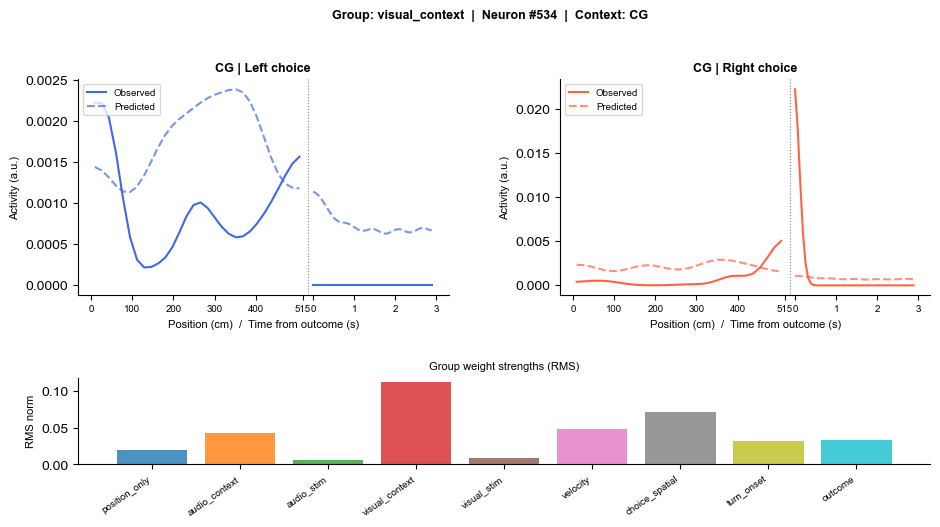

/var/folders/tb/ct0s7r6j0q90l_p7cs6hshr80000gn/T/ipykernel_66194/3267886323.py:34: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


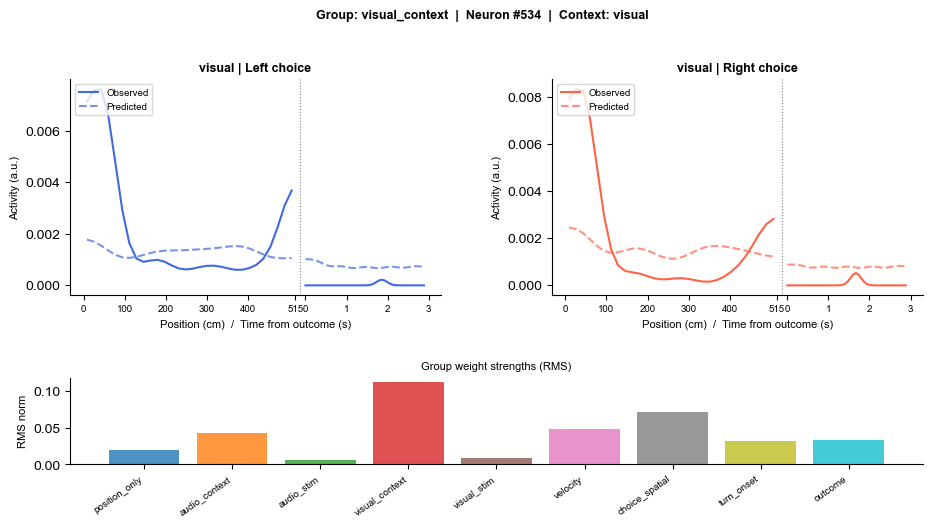

/var/folders/tb/ct0s7r6j0q90l_p7cs6hshr80000gn/T/ipykernel_66194/3267886323.py:34: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


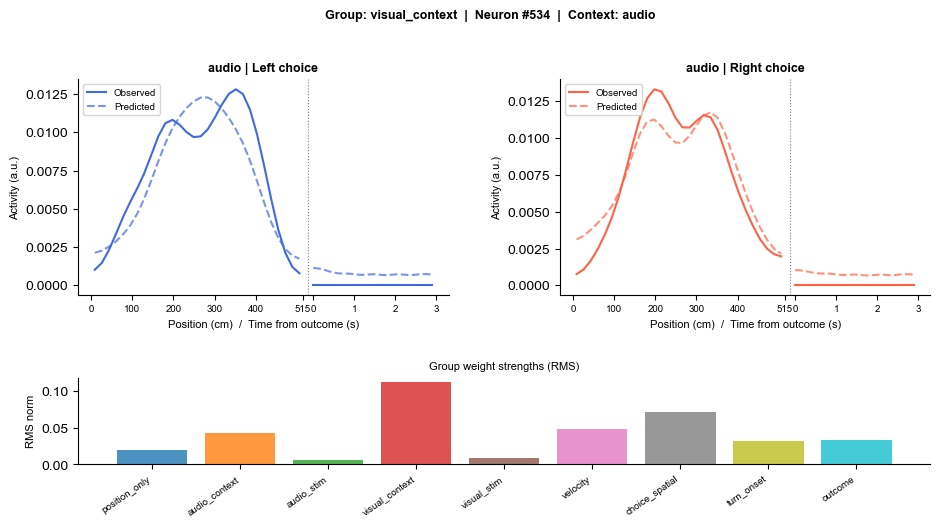

/var/folders/tb/ct0s7r6j0q90l_p7cs6hshr80000gn/T/ipykernel_66194/3267886323.py:34: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


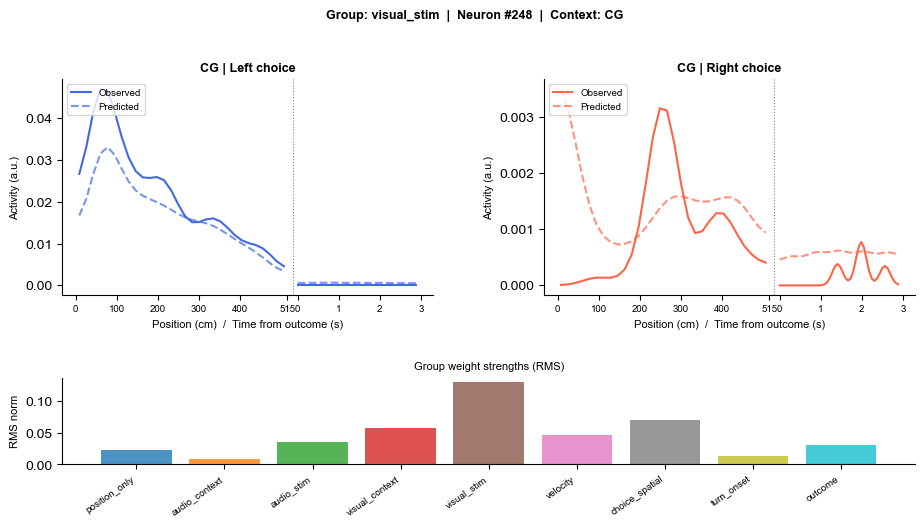

/var/folders/tb/ct0s7r6j0q90l_p7cs6hshr80000gn/T/ipykernel_66194/3267886323.py:34: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


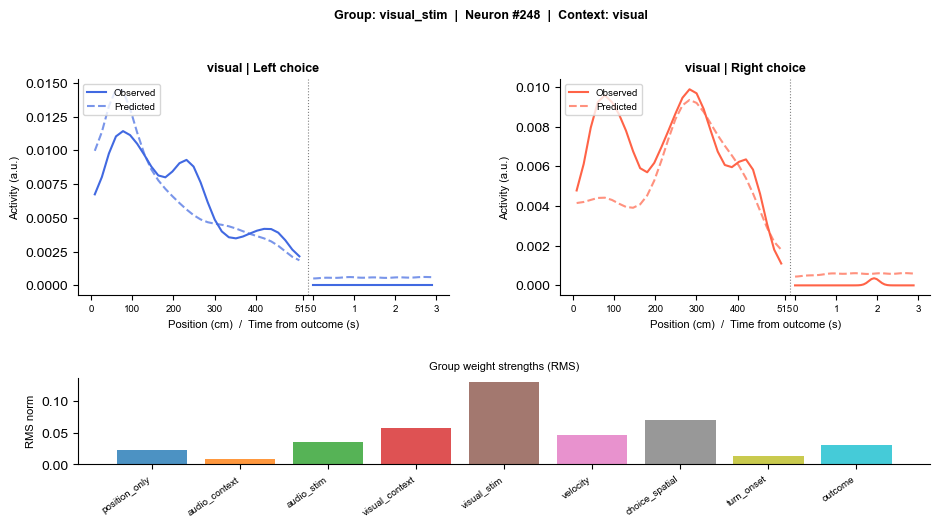

/var/folders/tb/ct0s7r6j0q90l_p7cs6hshr80000gn/T/ipykernel_66194/3267886323.py:34: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


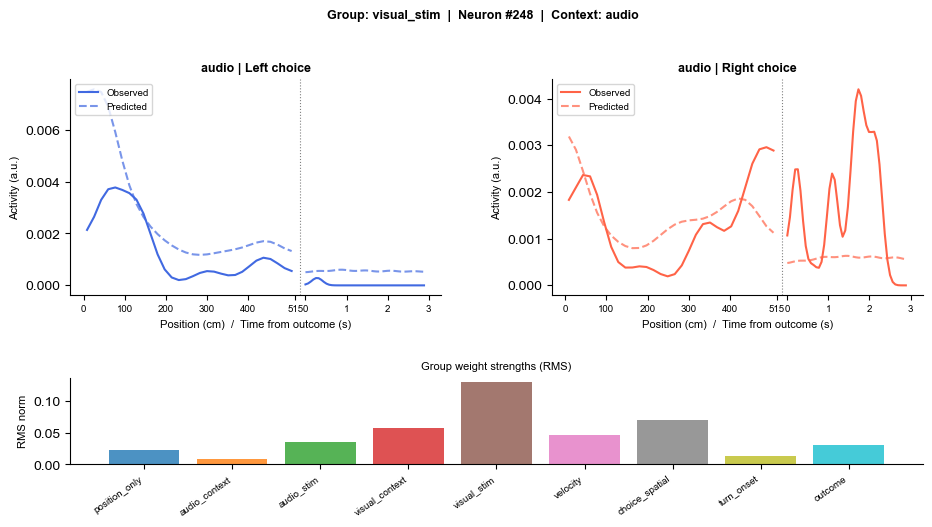

/var/folders/tb/ct0s7r6j0q90l_p7cs6hshr80000gn/T/ipykernel_66194/3267886323.py:34: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


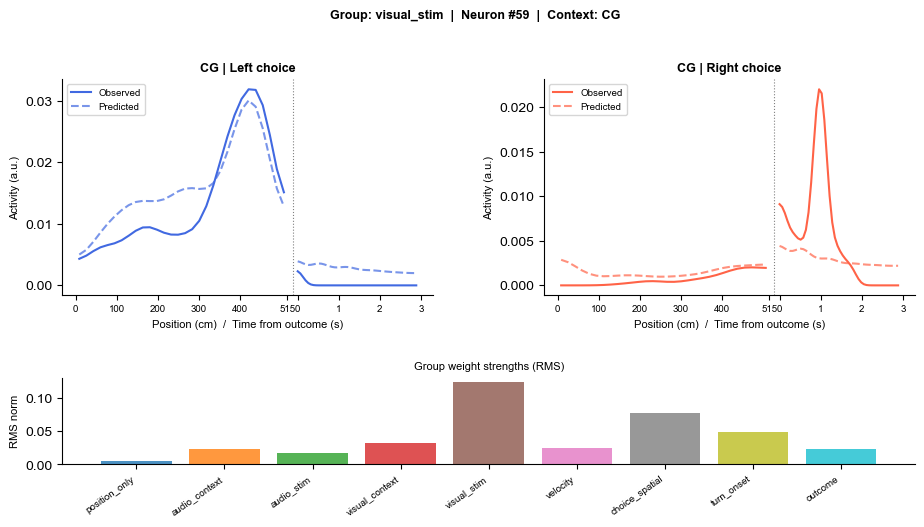

/var/folders/tb/ct0s7r6j0q90l_p7cs6hshr80000gn/T/ipykernel_66194/3267886323.py:34: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


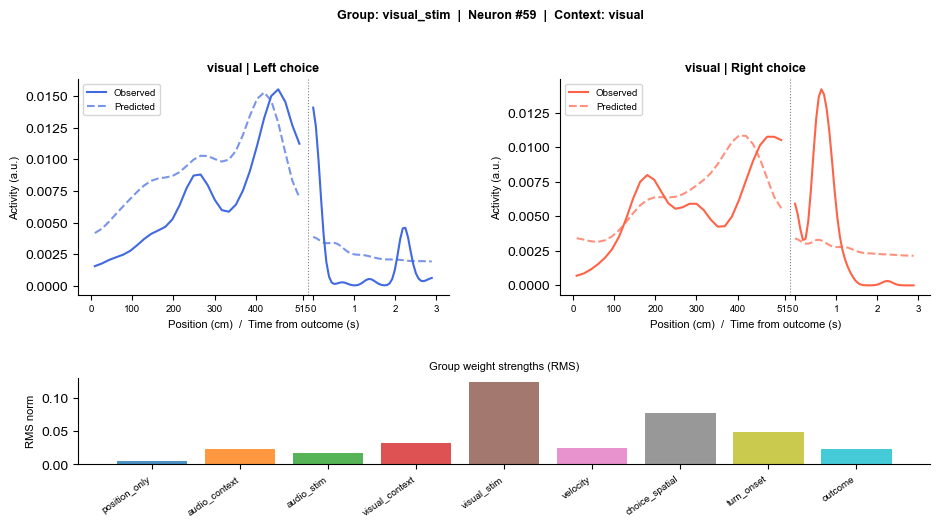

/var/folders/tb/ct0s7r6j0q90l_p7cs6hshr80000gn/T/ipykernel_66194/3267886323.py:34: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


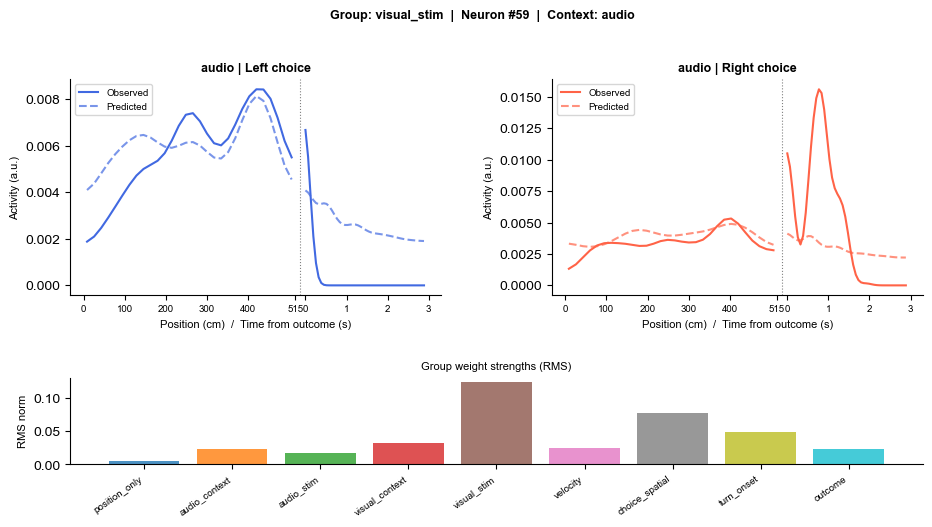

/var/folders/tb/ct0s7r6j0q90l_p7cs6hshr80000gn/T/ipykernel_66194/3267886323.py:34: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


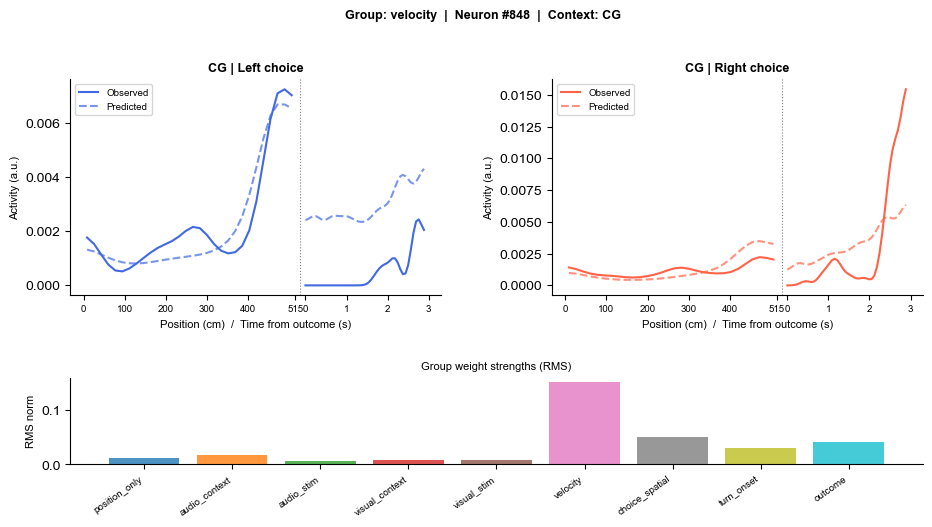

/var/folders/tb/ct0s7r6j0q90l_p7cs6hshr80000gn/T/ipykernel_66194/3267886323.py:34: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


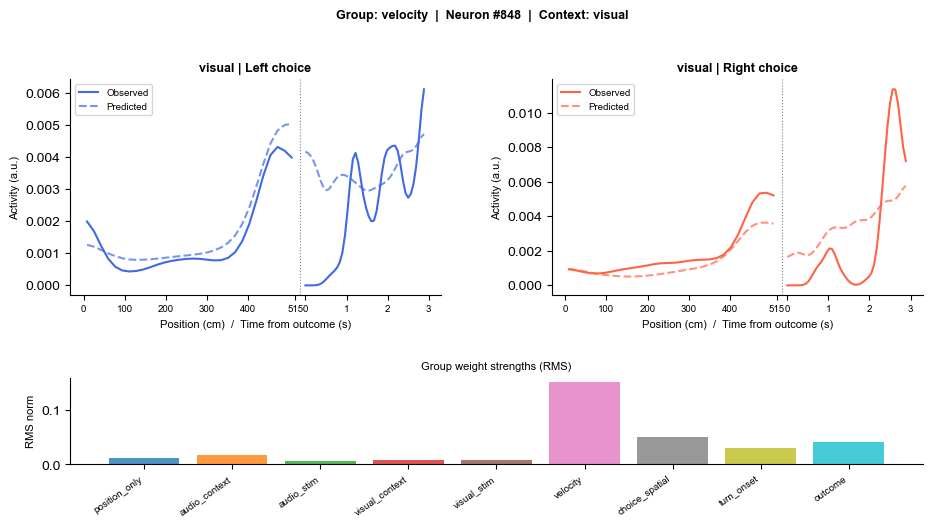

/var/folders/tb/ct0s7r6j0q90l_p7cs6hshr80000gn/T/ipykernel_66194/3267886323.py:34: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


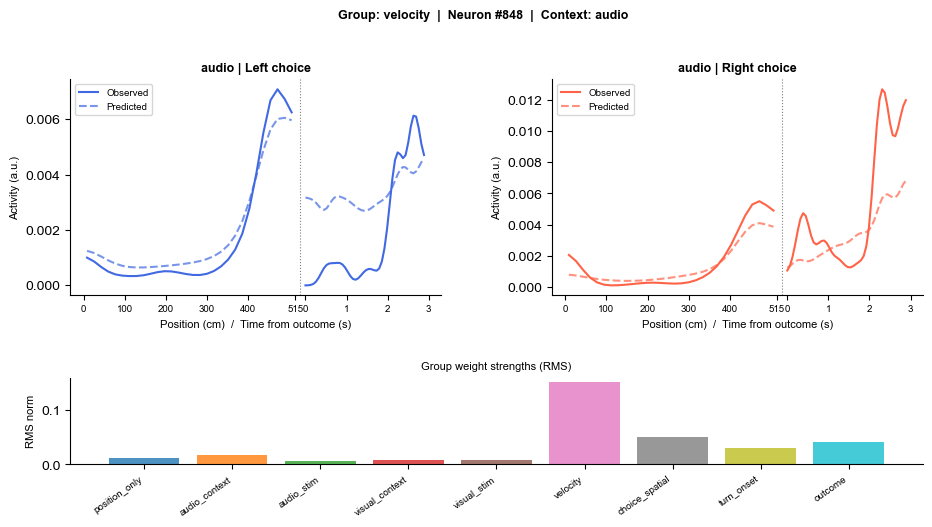

/var/folders/tb/ct0s7r6j0q90l_p7cs6hshr80000gn/T/ipykernel_66194/3267886323.py:34: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


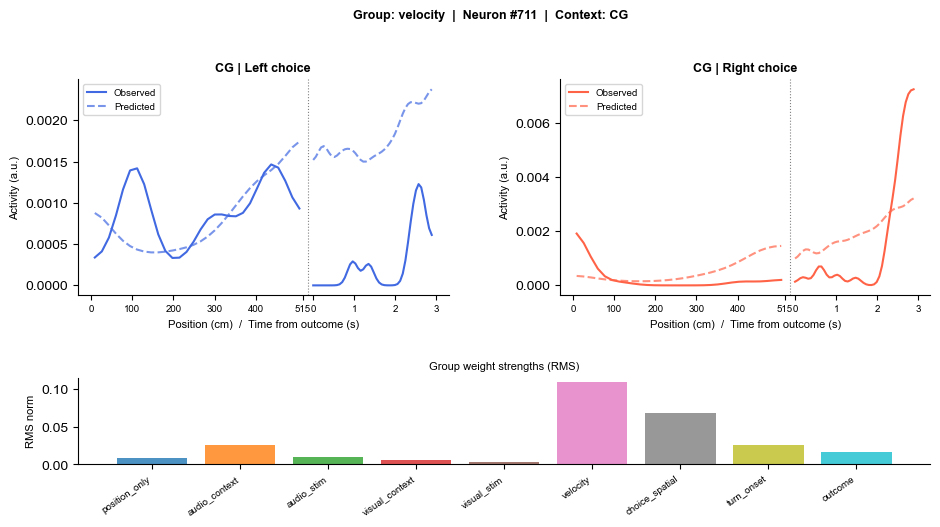

/var/folders/tb/ct0s7r6j0q90l_p7cs6hshr80000gn/T/ipykernel_66194/3267886323.py:34: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


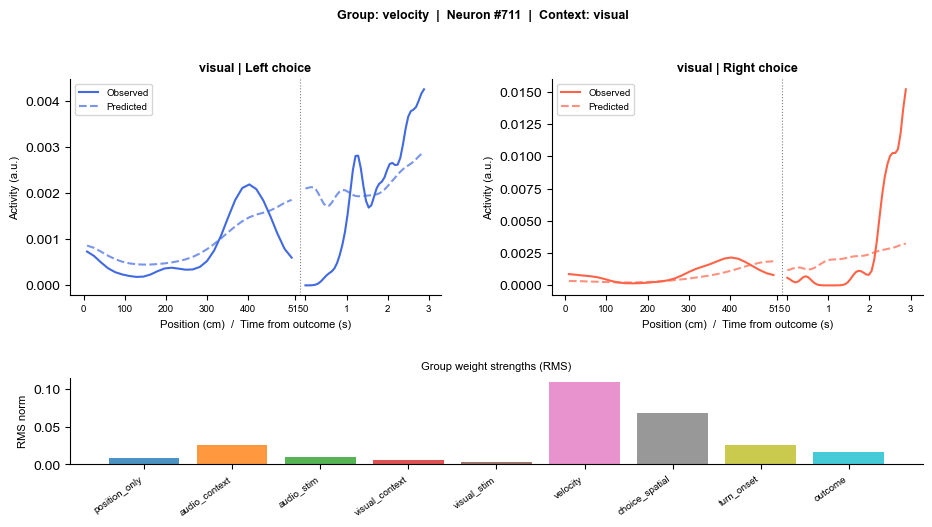

/var/folders/tb/ct0s7r6j0q90l_p7cs6hshr80000gn/T/ipykernel_66194/3267886323.py:34: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


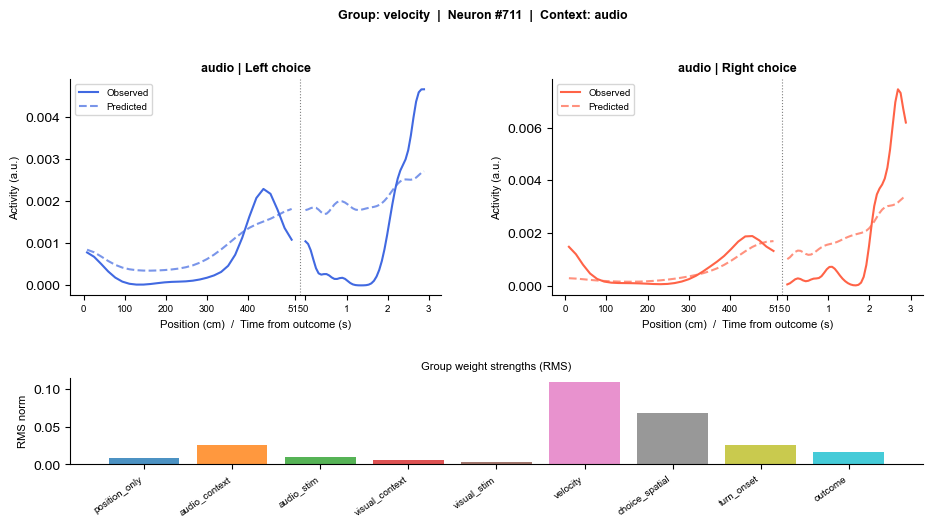

/var/folders/tb/ct0s7r6j0q90l_p7cs6hshr80000gn/T/ipykernel_66194/3267886323.py:34: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


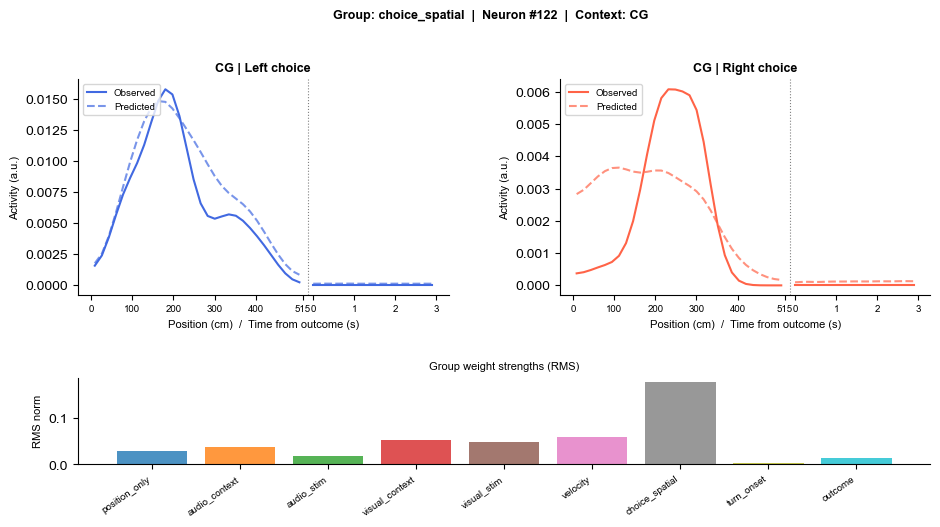

/var/folders/tb/ct0s7r6j0q90l_p7cs6hshr80000gn/T/ipykernel_66194/3267886323.py:34: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


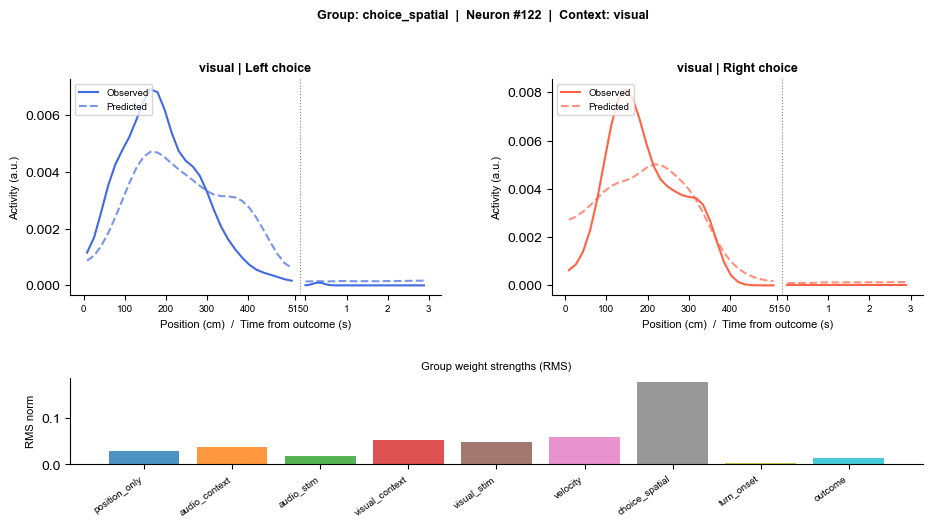

/var/folders/tb/ct0s7r6j0q90l_p7cs6hshr80000gn/T/ipykernel_66194/3267886323.py:34: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


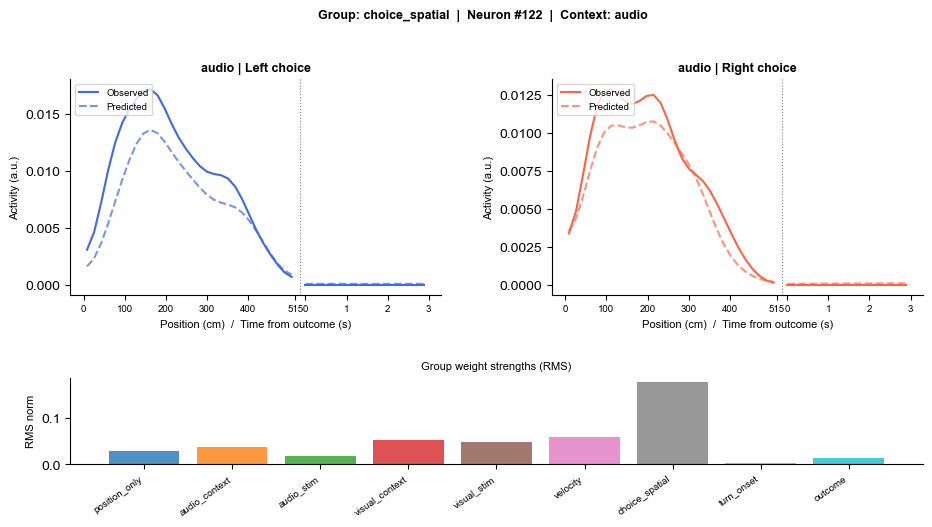

/var/folders/tb/ct0s7r6j0q90l_p7cs6hshr80000gn/T/ipykernel_66194/3267886323.py:34: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


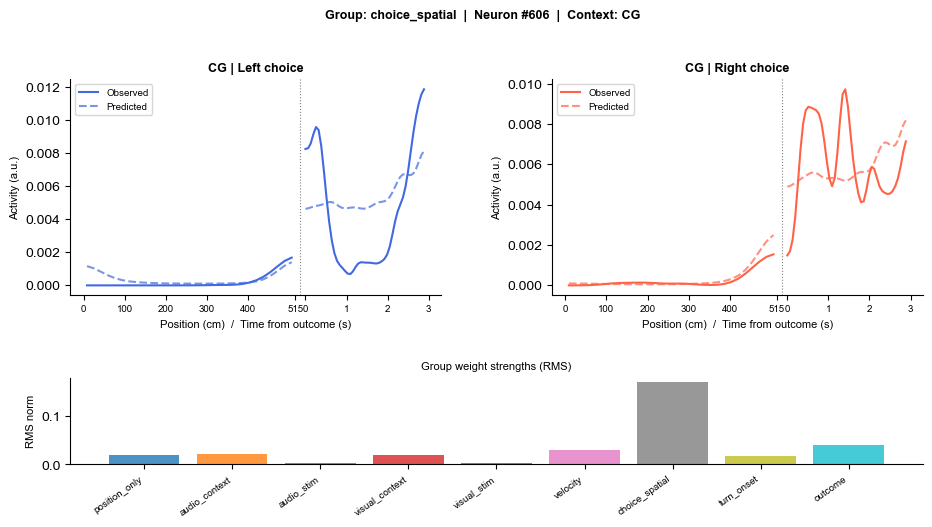

/var/folders/tb/ct0s7r6j0q90l_p7cs6hshr80000gn/T/ipykernel_66194/3267886323.py:34: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


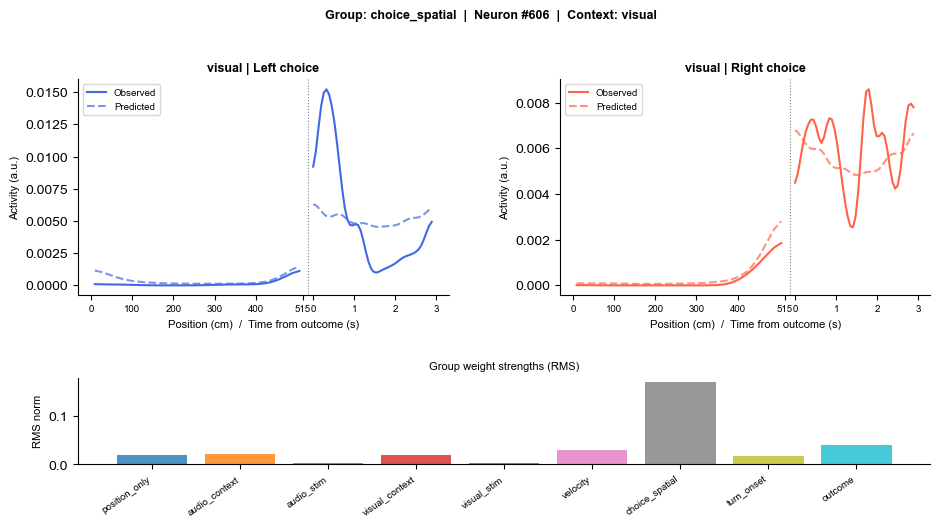

/var/folders/tb/ct0s7r6j0q90l_p7cs6hshr80000gn/T/ipykernel_66194/3267886323.py:34: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


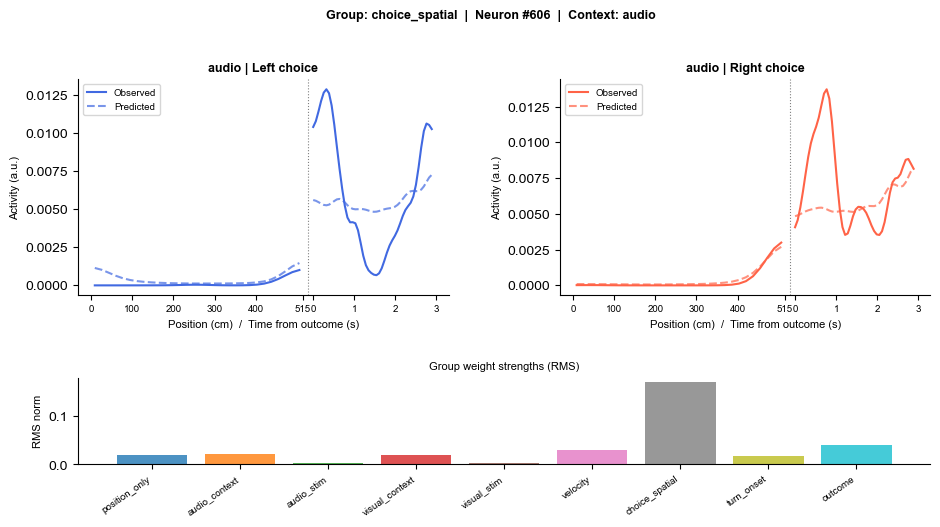

/var/folders/tb/ct0s7r6j0q90l_p7cs6hshr80000gn/T/ipykernel_66194/3267886323.py:34: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


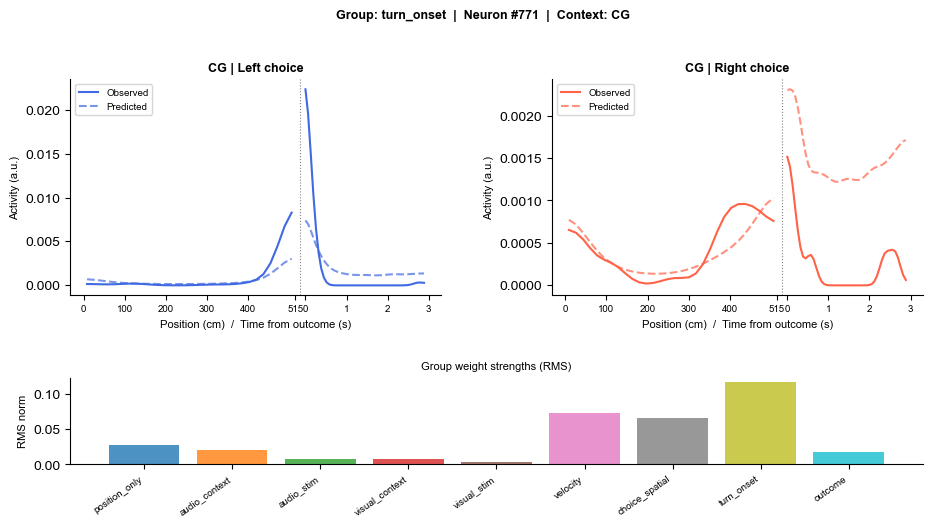

/var/folders/tb/ct0s7r6j0q90l_p7cs6hshr80000gn/T/ipykernel_66194/3267886323.py:34: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


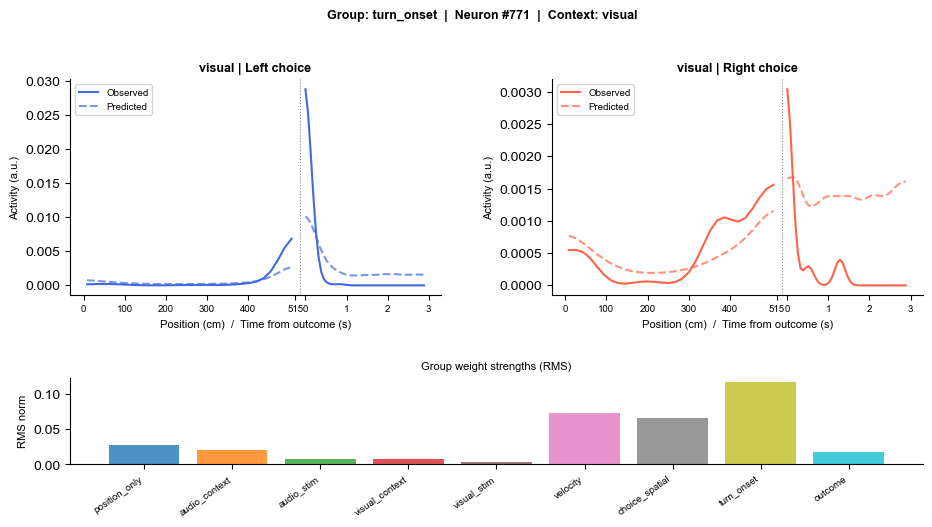

/var/folders/tb/ct0s7r6j0q90l_p7cs6hshr80000gn/T/ipykernel_66194/3267886323.py:34: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


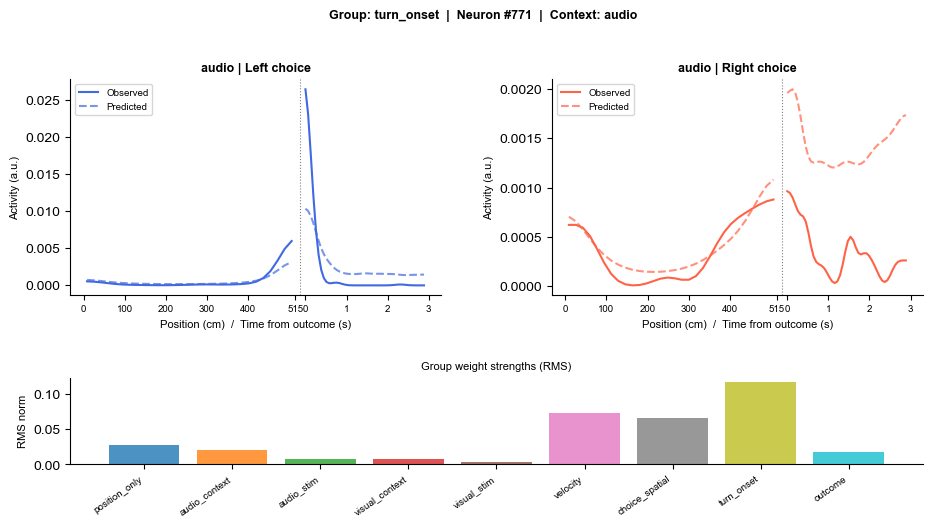

/var/folders/tb/ct0s7r6j0q90l_p7cs6hshr80000gn/T/ipykernel_66194/3267886323.py:34: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


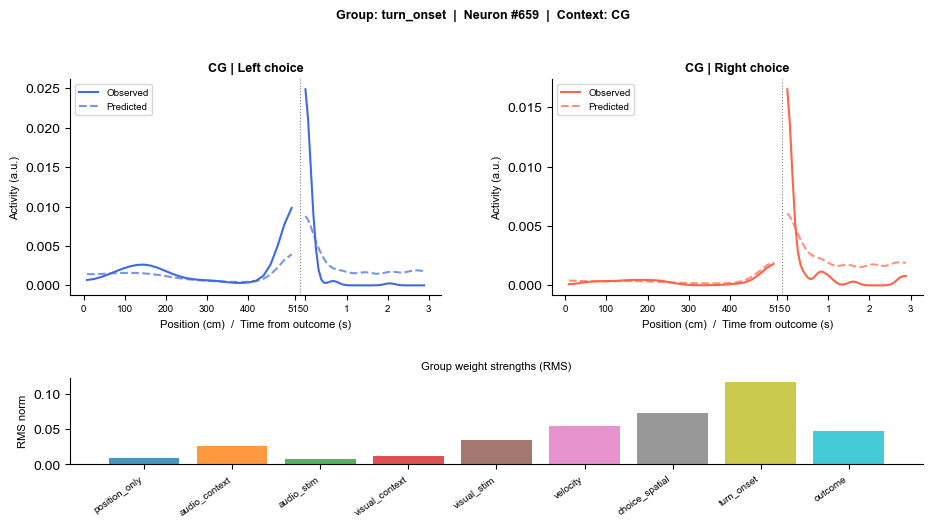

/var/folders/tb/ct0s7r6j0q90l_p7cs6hshr80000gn/T/ipykernel_66194/3267886323.py:34: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


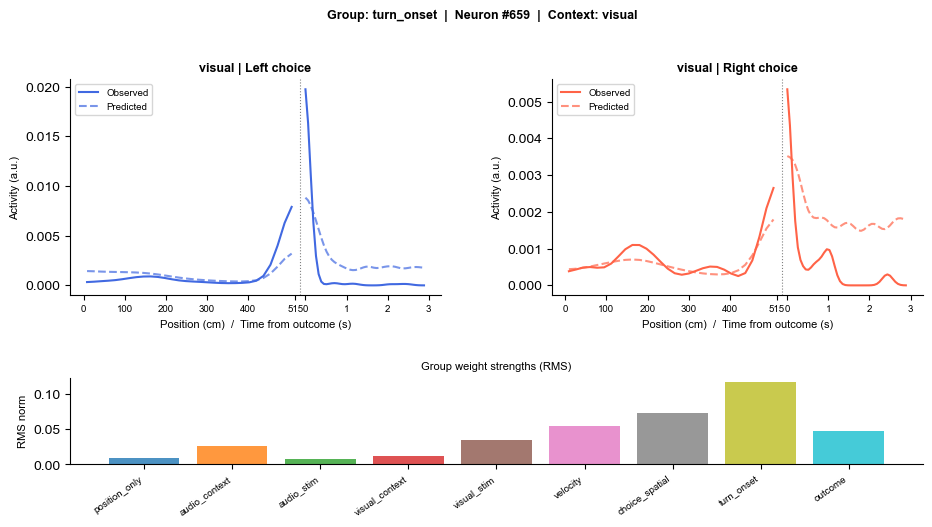

/var/folders/tb/ct0s7r6j0q90l_p7cs6hshr80000gn/T/ipykernel_66194/3267886323.py:34: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


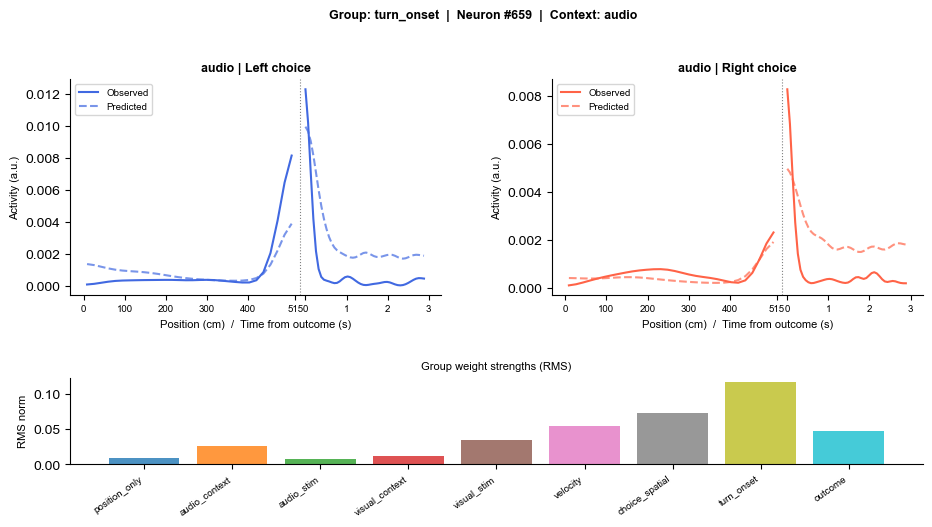

/var/folders/tb/ct0s7r6j0q90l_p7cs6hshr80000gn/T/ipykernel_66194/3267886323.py:34: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


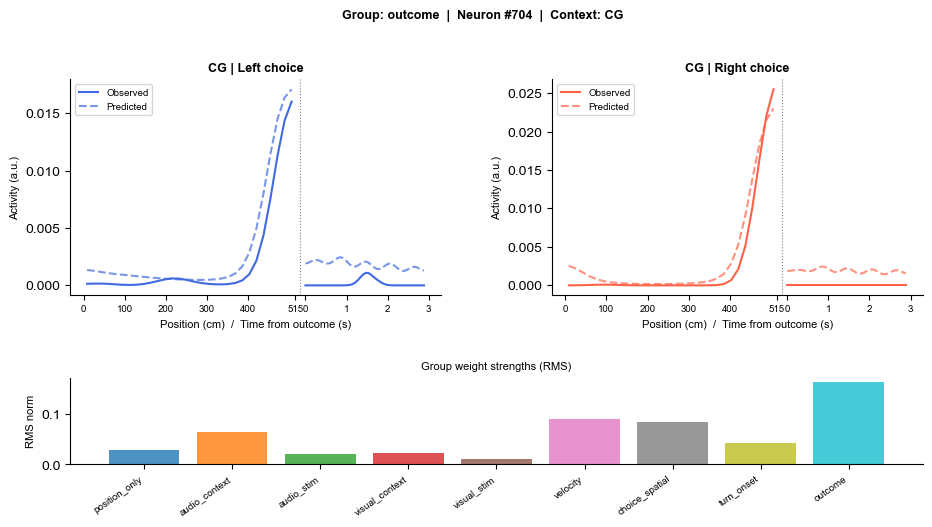

/var/folders/tb/ct0s7r6j0q90l_p7cs6hshr80000gn/T/ipykernel_66194/3267886323.py:34: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


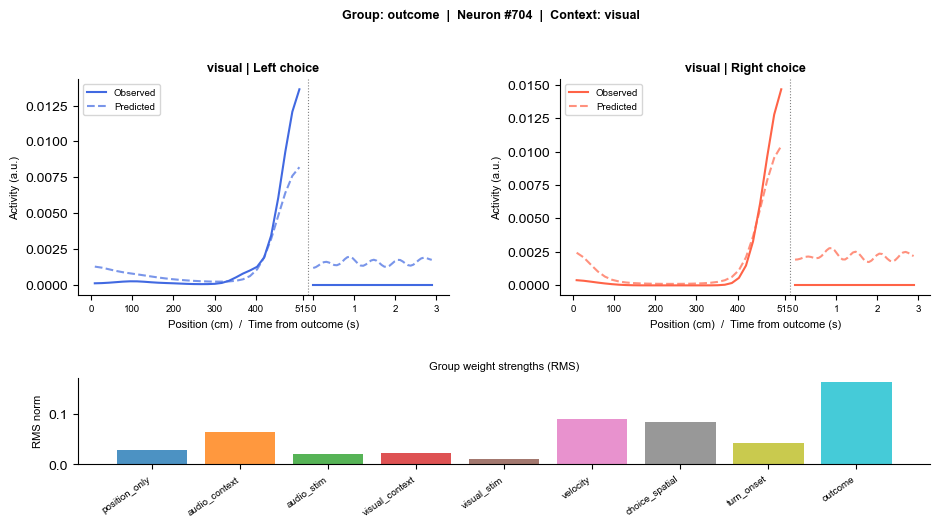

/var/folders/tb/ct0s7r6j0q90l_p7cs6hshr80000gn/T/ipykernel_66194/3267886323.py:34: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


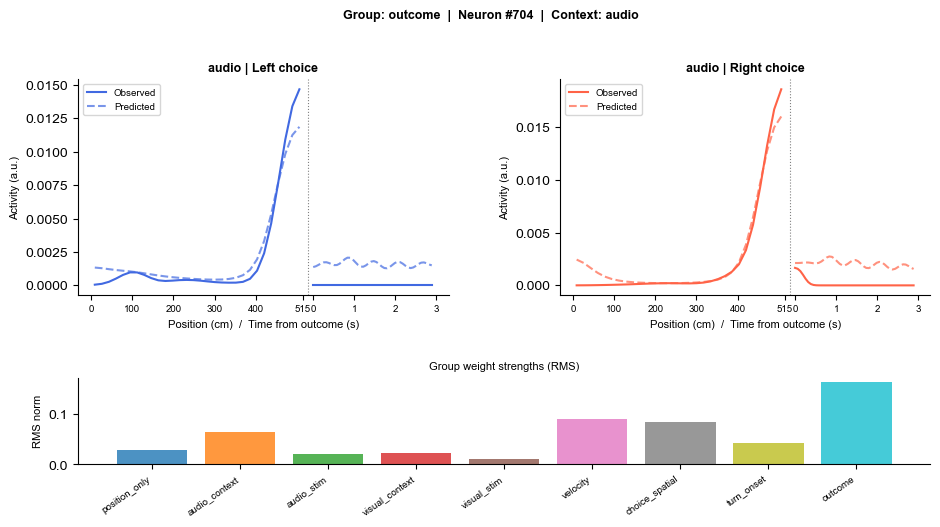

/var/folders/tb/ct0s7r6j0q90l_p7cs6hshr80000gn/T/ipykernel_66194/3267886323.py:34: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


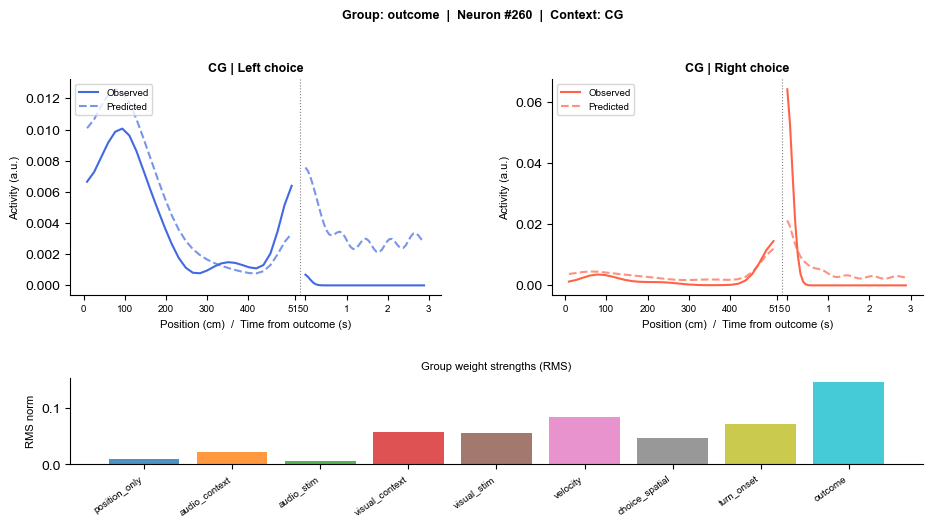

/var/folders/tb/ct0s7r6j0q90l_p7cs6hshr80000gn/T/ipykernel_66194/3267886323.py:34: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


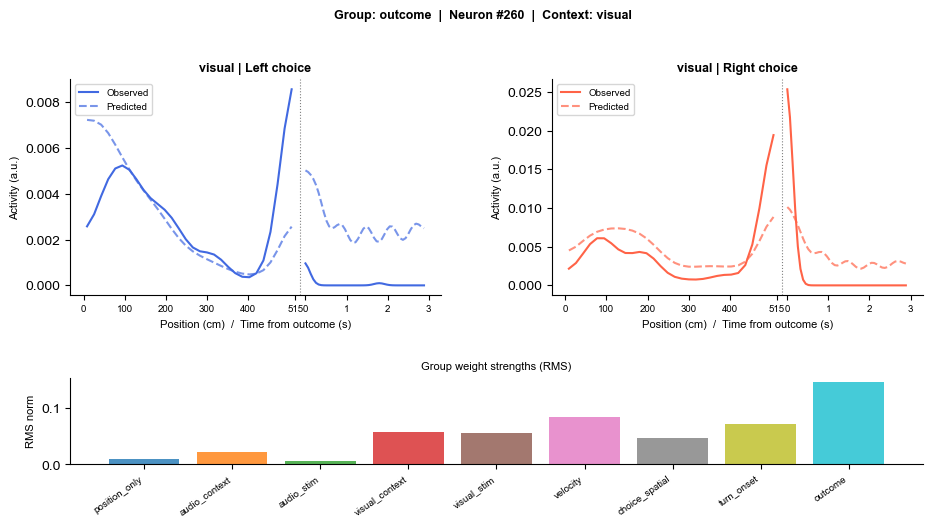

/var/folders/tb/ct0s7r6j0q90l_p7cs6hshr80000gn/T/ipykernel_66194/3267886323.py:34: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


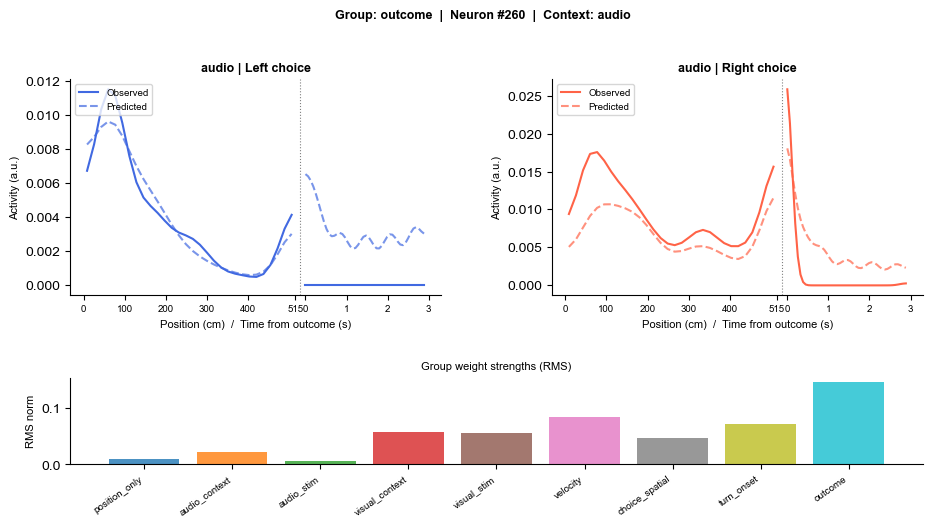

In [23]:
# Plot top neurons per group -- one figure per neuron x context
condition = 'choice'   # 'choice' or 'stimulus'

context_names = {0: 'CG', 1: 'visual', 2: 'audio'}

for group_name, neuron_list in top_neurons.items():
    if not neuron_list:
        print(f'  [skip] {group_name}: no neurons')
        continue
    for neuron_idx in neuron_list:
        for ctx in [0, 1, 2]:
            fig = plot_model_fit_neuron(
                neuron_idx     = neuron_idx,
                ctx            = ctx,
                all_results    = all_results,
                glm_data_dict  = glm_data_dict,
                metadata       = metadata,
                X              = X,
                Y              = Y,
                predictor_info = predictor_info,
                condition      = condition,
                n_pos_bins     = 30,
                post_iti_seconds = 3.0,
                sampling_rate  = 15.6,
                smooth_sigma   = 2,
                gap            = 25,
                figsize        = (11, 5),
            )
            fig.suptitle(
                f'Group: {group_name}  |  Neuron #{neuron_idx}  |  '
                f'Context: {context_names[ctx]}',
                fontsize=9, fontweight='bold', y=1.02,
            )
            plt.tight_layout()
            plt.show()